# Cell segmentation -- decision tree and algorithms

This figure documents the logic of
[`2.segment_images/notebooks/5.cell_segmentation.ipynb`](../../../2.segment_images/notebooks/5.cell_segmentation.ipynb),
which turns a per-organoid cytoplasm (AGP) signal and an existing nuclei
label mask into a cell label mask, a refined cell mask, and a cytoplasm
mask.

The cell-level segmentation is **morphology-dependent**: it first looks up
a per-FOV organoid-shape label (`globular`, `cluster`, `small`,
`dissociated`, `elongated`, `failed`, or `blank`) from
`2.segment_images/image_labels/segmentation_classes.parquet`, and that
label selects a different pre-processing recipe before a shared 3D
watershed step. Everything below is read directly out of
`image_analysis_3D.segmentation_utils.cell_segmentation` and
`image_analysis_3D.segmentation_utils.general_segmentation_utils` -- the
box text quotes the actual function calls and parameter values, not a
paraphrase.

One figure: a decision-tree / pipeline flowchart -- every branch, shared
step, and post-processing step in the notebook, drawn as polygons
(octagonal process boxes, a diamond decision node, arrows for control
flow) -- with a small framed thumbnail inset next to each image-producing
step, showing what that step actually does to a small synthetic 2D
stand-in for the AGP channel (smoothing, thresholding, dilation, the
Sobel elevation map, the resulting watershed labels). **The thumbnails are
illustrative only, not real microscopy data** -- they loosely resemble
each morphology class (a tight overlapping cluster, several separated
small blobs, elongated rod-like objects) purely so the effect of each
operation is visible next to the code that produces it, rather than
split into a separate figure.


In [1]:
import re
import textwrap

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.font_manager import FontProperties
from matplotlib.patches import FancyArrowPatch, Polygon, Rectangle
from matplotlib.path import Path
from skimage.filters import butterworth, gaussian, sobel, threshold_otsu
from skimage.morphology import dilation, disk
from skimage.segmentation import watershed

plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["savefig.facecolor"] = "white"

## Drawing primitives

The figure is laid out in **inches**: one axes fills the whole canvas and
its limits equal the figure size, so one data unit is one inch. That lets
every box measure its text with the real renderer, wrap it to the box's
width, and grow downward to fit -- and lets the finished figure be cropped
to its content so there is no empty canvas left over.

- `box` -- rounded-rect node anchored at its top edge. Title is bold sans;
  body paragraphs wrapped in backticks are set in monospace (code). Optional
  toy-data `thumbs` sit *inside* the box on its right.
- `row` -- several boxes sharing a top edge, all grown to the tallest one.
- `diamond` -- the single decision node.
- `flow` -- an orthogonal connector through a list of points, with an arrowhead.
- `thumb` -- a framed inset of a real toy-data result.

In [2]:
# Layout units are INCHES: the figure's single axes fills the whole canvas
# and xlim/ylim are set equal to the figure size, so 1 data unit == 1 inch.
# That makes text measurement exact (no aspect-ratio guesswork) and lets the
# figure be cropped to its content at the end with zero leftover whitespace.

FONT_SANS = ["sans-serif"]
FONT_MONO = ["Liberation Mono"]

PALETTE = {  # kind -> (fill, edge)
    "io": ("#eef2f5", "#8fa3b0"),
    "decision": ("#fff0c2", "#d1a12a"),
    "panel": ("#f1f8ee", "#a9d0a0"),
    "sub": ("#ffffff", "#93c48a"),
    "shared": ("#e1eefa", "#6b9dcc"),
    "post": ("#efe8f7", "#9b84c5"),
    "skip": ("#f0f2f4", "#90a0aa"),
    "error": ("#fce6ea", "#cf6479"),
    "terminal": ("#d6f0ea", "#4ea394"),
}
INK = "#1b2631"
MUTED = "#5a6a74"
ARROW_C = "#5d717d"

TITLE_SIZE = 13.5
BODY_SIZE = 11.5


# ------------------------------------------------------------ geometry ----
def _round_vertex(P, V, N, radius, n=7):
    P, V, N = np.array(P, float), np.array(V, float), np.array(N, float)
    din = (V - P) / np.linalg.norm(V - P)
    dout = (N - V) / np.linalg.norm(N - V)
    A, B = V - din * radius, V + dout * radius
    return [
        tuple((1 - t) ** 2 * A + 2 * (1 - t) * t * V + t**2 * B)
        for t in np.linspace(0, 1, n)
    ]


def _rounded_points(vertices, radius, n=7):
    pts, m = [], len(vertices)
    for i in range(m):
        P, V, N = vertices[i - 1], vertices[i], vertices[(i + 1) % m]
        r = min(
            radius,
            0.45 * np.linalg.norm(np.subtract(V, P)),
            0.45 * np.linalg.norm(np.subtract(N, V)),
        )
        pts.extend(_round_vertex(P, V, N, r, n))
    return pts


def _rrect(
    ax, x0, y0, x1, y1, kind, dashed=False, radius=0.12, lw=1.3, zorder=2, frame=True
):
    fill, edge = PALETTE[kind]
    ax.add_patch(
        Polygon(
            _rounded_points([(x0, y0), (x1, y0), (x1, y1), (x0, y1)], radius),
            closed=True,
            facecolor=fill,
            edgecolor=edge if frame else "none",
            linewidth=lw,
            linestyle=(0, (4, 2.5)) if dashed else "-",
            zorder=zorder,
        )
    )


# -------------------------------------------------------- text measuring --
def _text_w(ax, s, size, weight="normal", family=FONT_SANS):
    fp = FontProperties(family=family, size=size, weight=weight)
    w, _, _ = ax.figure.canvas.get_renderer().get_text_width_height_descent(
        s, fp, ismath=False
    )
    return w / ax.figure.dpi


def _split_long(ax, word, width, size, weight, family):
    """Break a single over-long token (e.g. a long identifier) after _ , ( . chars."""
    parts = re.split(r"(?<=[_,(.=])", word)
    out, cur = [], ""
    for p in parts:
        if cur and _text_w(ax, cur + p, size, weight, family) > width:
            out.append(cur)
            cur = p
        else:
            cur += p
    return out + [cur]


def wrap_text(ax, text, width, size, weight="normal", family=FONT_SANS):
    """Greedy word-wrap using real rendered widths (not a char-count guess)."""
    lines = []
    for para in text.split("\n"):
        cur = ""
        for word in para.split(" "):
            pieces = (
                [word]
                if _text_w(ax, word, size, weight, family) <= width
                else _split_long(ax, word, width, size, weight, family)
            )
            for i, piece in enumerate(pieces):
                sep = " " if (i == 0 and cur) else ""
                trial = cur + sep + piece
                if not cur or _text_w(ax, trial, size, weight, family) <= width:
                    cur = trial
                else:
                    lines.append(cur)
                    cur = piece
        lines.append(cur)
    return lines


def _layout_text(ax, title, body, width, title_size, body_size):
    """Returns a list of (line, size, weight, family, line_height) rows.
    Body paragraphs wrapped in backticks are set in monospace (code)."""
    rows = []
    if title:
        lh = title_size * 1.28 / 72
        rows += [
            (l, title_size, "bold", FONT_SANS, lh)
            for l in wrap_text(ax, title, width, title_size, "bold")
        ]
    if body:
        if rows:
            rows.append(("", body_size, "normal", FONT_SANS, 0.07))
        for para in body.split("\n"):
            mono = para.startswith("`") and para.endswith("`")
            fam = FONT_MONO if mono else FONT_SANS
            para = para.strip("`")
            lh = body_size * 1.36 / 72
            rows += [
                (l, body_size, "normal", fam, lh)
                for l in wrap_text(ax, para, width, body_size, family=fam)
            ]
    return rows


# ------------------------------------------------------------- box node ---
def box(
    ax,
    x0,
    x1,
    y1,
    title="",
    body="",
    kind="io",
    height=None,
    thumbs=(),
    thumb_size=0.8,
    title_size=TITLE_SIZE,
    body_size=BODY_SIZE,
    dashed=False,
    frame=True,
    dry=False,
    pad_x=0.16,
    pad_y=0.14,
):
    """Rounded-rect node anchored at its TOP edge; wraps its text to its width
    and grows downward to fit. `thumbs` = [(img, cmap, caption), ...] are
    drawn inside the box, on its right. dry=True only measures the height."""
    n_th = len(thumbs)
    th_w = n_th * thumb_size + max(0, n_th - 1) * 0.12 + (0.16 if n_th else 0)
    text_w = (x1 - x0) - 2 * pad_x - th_w
    rows = _layout_text(ax, title, body, text_w, title_size, body_size)
    text_h = sum(r[4] for r in rows)
    has_cap = any(t[2] for t in thumbs)
    th_h = (thumb_size + (0.22 if has_cap else 0)) if n_th else 0
    h = 2 * pad_y + max(text_h, th_h)
    if height is not None:
        h = max(h, height)
    if dry:
        return h
    y0 = y1 - h
    cy = (y0 + y1) / 2
    _rrect(ax, x0, y0, x1, y1, kind, dashed=dashed, frame=frame)

    y = cy + text_h / 2
    for line, size, weight, fam, lh in rows:
        if line:
            ax.text(
                x0 + pad_x,
                y - lh / 2,
                line,
                ha="left",
                va="center",
                fontsize=size,
                fontweight=weight,
                family=fam,
                color=INK,
                zorder=4,
            )
        y -= lh

    tx = x1 - pad_x - n_th * thumb_size - max(0, n_th - 1) * 0.12
    ty1 = cy + th_h / 2
    for img, cmap, cap in thumbs:
        thumb(ax, tx, ty1 - thumb_size, tx + thumb_size, ty1, img, cmap)
        if cap:
            ax.text(
                tx + thumb_size / 2,
                ty1 - thumb_size - 0.04,
                cap,
                ha="center",
                va="top",
                fontsize=10,
                style="italic",
                color=MUTED,
                zorder=4,
            )
        tx += thumb_size + 0.12
    return dict(x0=x0, x1=x1, y0=y0, y1=y1, cx=(x0 + x1) / 2, cy=cy, h=h)


def row(ax, y1, specs, **common):
    """Boxes sharing a top edge, all grown to the tallest one's height."""
    h = max(box(ax, **{**common, **s}, y1=y1, dry=True) for s in specs)
    return [box(ax, **{**common, **s}, y1=y1, height=h) for s in specs]


def diamond(ax, cx, cy, w, h, title, subtitle=""):
    verts = [(cx, cy + h / 2), (cx + w / 2, cy), (cx, cy - h / 2), (cx - w / 2, cy)]
    fill, edge = PALETTE["decision"]
    ax.add_patch(
        Polygon(
            _rounded_points(verts, 0.18),
            closed=True,
            facecolor=fill,
            edgecolor=edge,
            linewidth=1.3,
            zorder=2,
        )
    )
    ax.text(
        cx,
        cy + (0.12 if subtitle else 0),
        title,
        ha="center",
        va="center",
        fontsize=14.5,
        fontweight="bold",
        color=INK,
        family=FONT_MONO,
        zorder=4,
    )
    if subtitle:
        ax.text(
            cx,
            cy - 0.2,
            subtitle,
            ha="center",
            va="center",
            fontsize=11.5,
            color=MUTED,
            zorder=4,
        )
    return dict(
        cx=cx,
        cy=cy,
        top=(cx, cy + h / 2),
        bottom=(cx, cy - h / 2),
        left=(cx - w / 2, cy),
        right=(cx + w / 2, cy),
    )


def flow(ax, *pts, color=ARROW_C, dashed=False, head=True, lw=1.5, zorder=1):
    """Orthogonal connector through the given points, arrowhead on the end."""
    path = Path(list(pts), [Path.MOVETO] + [Path.LINETO] * (len(pts) - 1))
    ax.add_patch(
        FancyArrowPatch(
            path=path,
            arrowstyle="-|>" if head else "-",
            mutation_scale=15,
            color=color,
            linewidth=lw,
            linestyle=(0, (4, 2.5)) if dashed else "-",
            shrinkA=0,
            shrinkB=0,
            joinstyle="miter",
            zorder=zorder,
        )
    )


def thumb(ax, x0, y0, x1, y1, img, cmap="inferno"):
    """Framed inset showing a real (toy-data) result of the adjacent step."""
    ax.imshow(
        img,
        extent=(x0, x1, y0, y1),
        origin="upper",
        cmap=cmap,
        aspect="auto",
        interpolation="nearest",
        zorder=3,
    )
    ax.add_patch(
        Rectangle(
            (x0, y0),
            x1 - x0,
            y1 - y0,
            fill=False,
            edgecolor="#37474f",
            linewidth=0.8,
            zorder=4,
        )
    )

## Toy data

Small synthetic single-slice stand-ins for the AGP channel -- **not real
data** -- one per morphology branch, run through that branch's *actual*
skimage calls (same function names and parameter values as
`cell_segmentation.py`) so the images shown in the flowchart below are
genuine outputs of those calls, not mockups.

In [3]:
def make_toy_cyto(kind, n=120, seed=0):
    rng = np.random.default_rng(seed)
    y, x = np.mgrid[:n, :n]
    img = 0.05 * rng.random((n, n))
    if kind == "globular / cluster":
        centers = [(45, 45), (50, 68), (68, 50), (70, 72)]
        for cy, cx in centers:
            img += np.exp(-((x - cx) ** 2 + (y - cy) ** 2) / (2 * 11**2))
        nuc_r = 5
    elif kind == "small / dissociated":
        centers = [(20, 20), (25, 95), (60, 30), (95, 60), (90, 95), (55, 70)]
        for cy, cx in centers:
            img += np.exp(-((x - cx) ** 2 + (y - cy) ** 2) / (2 * 6**2))
        nuc_r = 3
    elif kind == "elongated":
        centers = [(30, 60), (60, 60), (90, 60)]
        for cy, cx in centers:
            img += np.exp(-((x - cx) ** 2) / (2 * 28**2) - ((y - cy) ** 2) / (2 * 8**2))
        nuc_r = 4
    else:
        raise ValueError(kind)
    img = np.clip(img, 0, 1)
    nuclei = np.zeros((n, n), dtype=int)
    for lbl, (cy, cx) in enumerate(centers, 1):
        nuclei[((x - cx) ** 2 + (y - cy) ** 2) < nuc_r**2] = lbl
    return img, nuclei


BRANCH_PARAMS = {
    "globular / cluster": dict(
        sigma=2.5, dilate=None, extra_sigma=None, connectivity=1, compactness=1
    ),
    "small / dissociated": dict(
        sigma=3, dilate=1, extra_sigma=1, connectivity=1, compactness=0
    ),
    "elongated": dict(sigma=4, dilate=5, extra_sigma=1, connectivity=0, compactness=0),
}
SEEDS = {"globular / cluster": 1, "small / dissociated": 2, "elongated": 3}


def branch_pipeline(kind):
    cyto, nuclei = make_toy_cyto(kind, seed=SEEDS[kind])
    p = BRANCH_PARAMS[kind]
    bw = butterworth(
        cyto,
        cutoff_frequency_ratio=0.08,
        order=2,
        high_pass=False,
        squared_butterworth=False,
    )
    smoothed = gaussian(cyto, sigma=p["sigma"])
    thr = threshold_otsu(smoothed)
    binary = (smoothed > thr).astype(float)
    otsu = binary.copy()
    if p["dilate"]:
        binary = dilation(binary, disk(p["dilate"]))
    elevation = bw if p["extra_sigma"] is None else gaussian(bw, sigma=p["extra_sigma"])
    elevation = sobel(elevation)
    labels = watershed(
        elevation,
        markers=nuclei,
        connectivity=max(p["connectivity"], 1),
        compactness=p["compactness"],
        mask=binary,
    )
    return dict(
        cyto=cyto,
        butterworth=bw,
        smoothed=smoothed,
        otsu=otsu,
        binary=binary,
        elevation=elevation,
        labels=labels,
    )


RESULTS = {k: branch_pipeline(k) for k in BRANCH_PARAMS}
BRANCH_TAGS = {
    "globular / cluster": "glob.",
    "small / dissociated": "small",
    "elongated": "elong.",
}

## Figure -- decision tree, algorithms, and toy-data visuals, combined

The flow reads as a **snake**: inputs and the morphology decision run
left -> right; the shared Butterworth filter feeds three branch panels (each
with a *threshold-mask* lane and an *elevation-map* lane converging on its
3D watershed); the watershed outputs merge into the cell-mask row (left ->
right), turn down into post-hoc refinement (right -> left), and finish with
cytoplasm, border cleanup and saving (left -> right). `failed` / `blank`
labels take the dashed path down the right margin straight to `cell_mask`.

Every framed thumbnail is the real output of the adjacent step's code, run
on the toy data above. The shared Butterworth box carries one result per
branch (`glob.` / `small` / `elong.`) since the code is shared but each
branch feeds it a different signal.

/tmp/ipykernel_4021792/675147734.py:59: UserWarning: Glyph 8712 (\N{ELEMENT OF}) missing from font(s) Liberation Mono.
  w, _, _ = ax.figure.canvas.get_renderer().get_text_width_height_descent(s, fp, ismath=False)
/home/lippincm/Documents/NF1_3D_organoid_profiling_pipeline/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8712 (\N{ELEMENT OF}) missing from font(s) Liberation Mono.
  fig.canvas.print_figure(bytes_io, **kw)


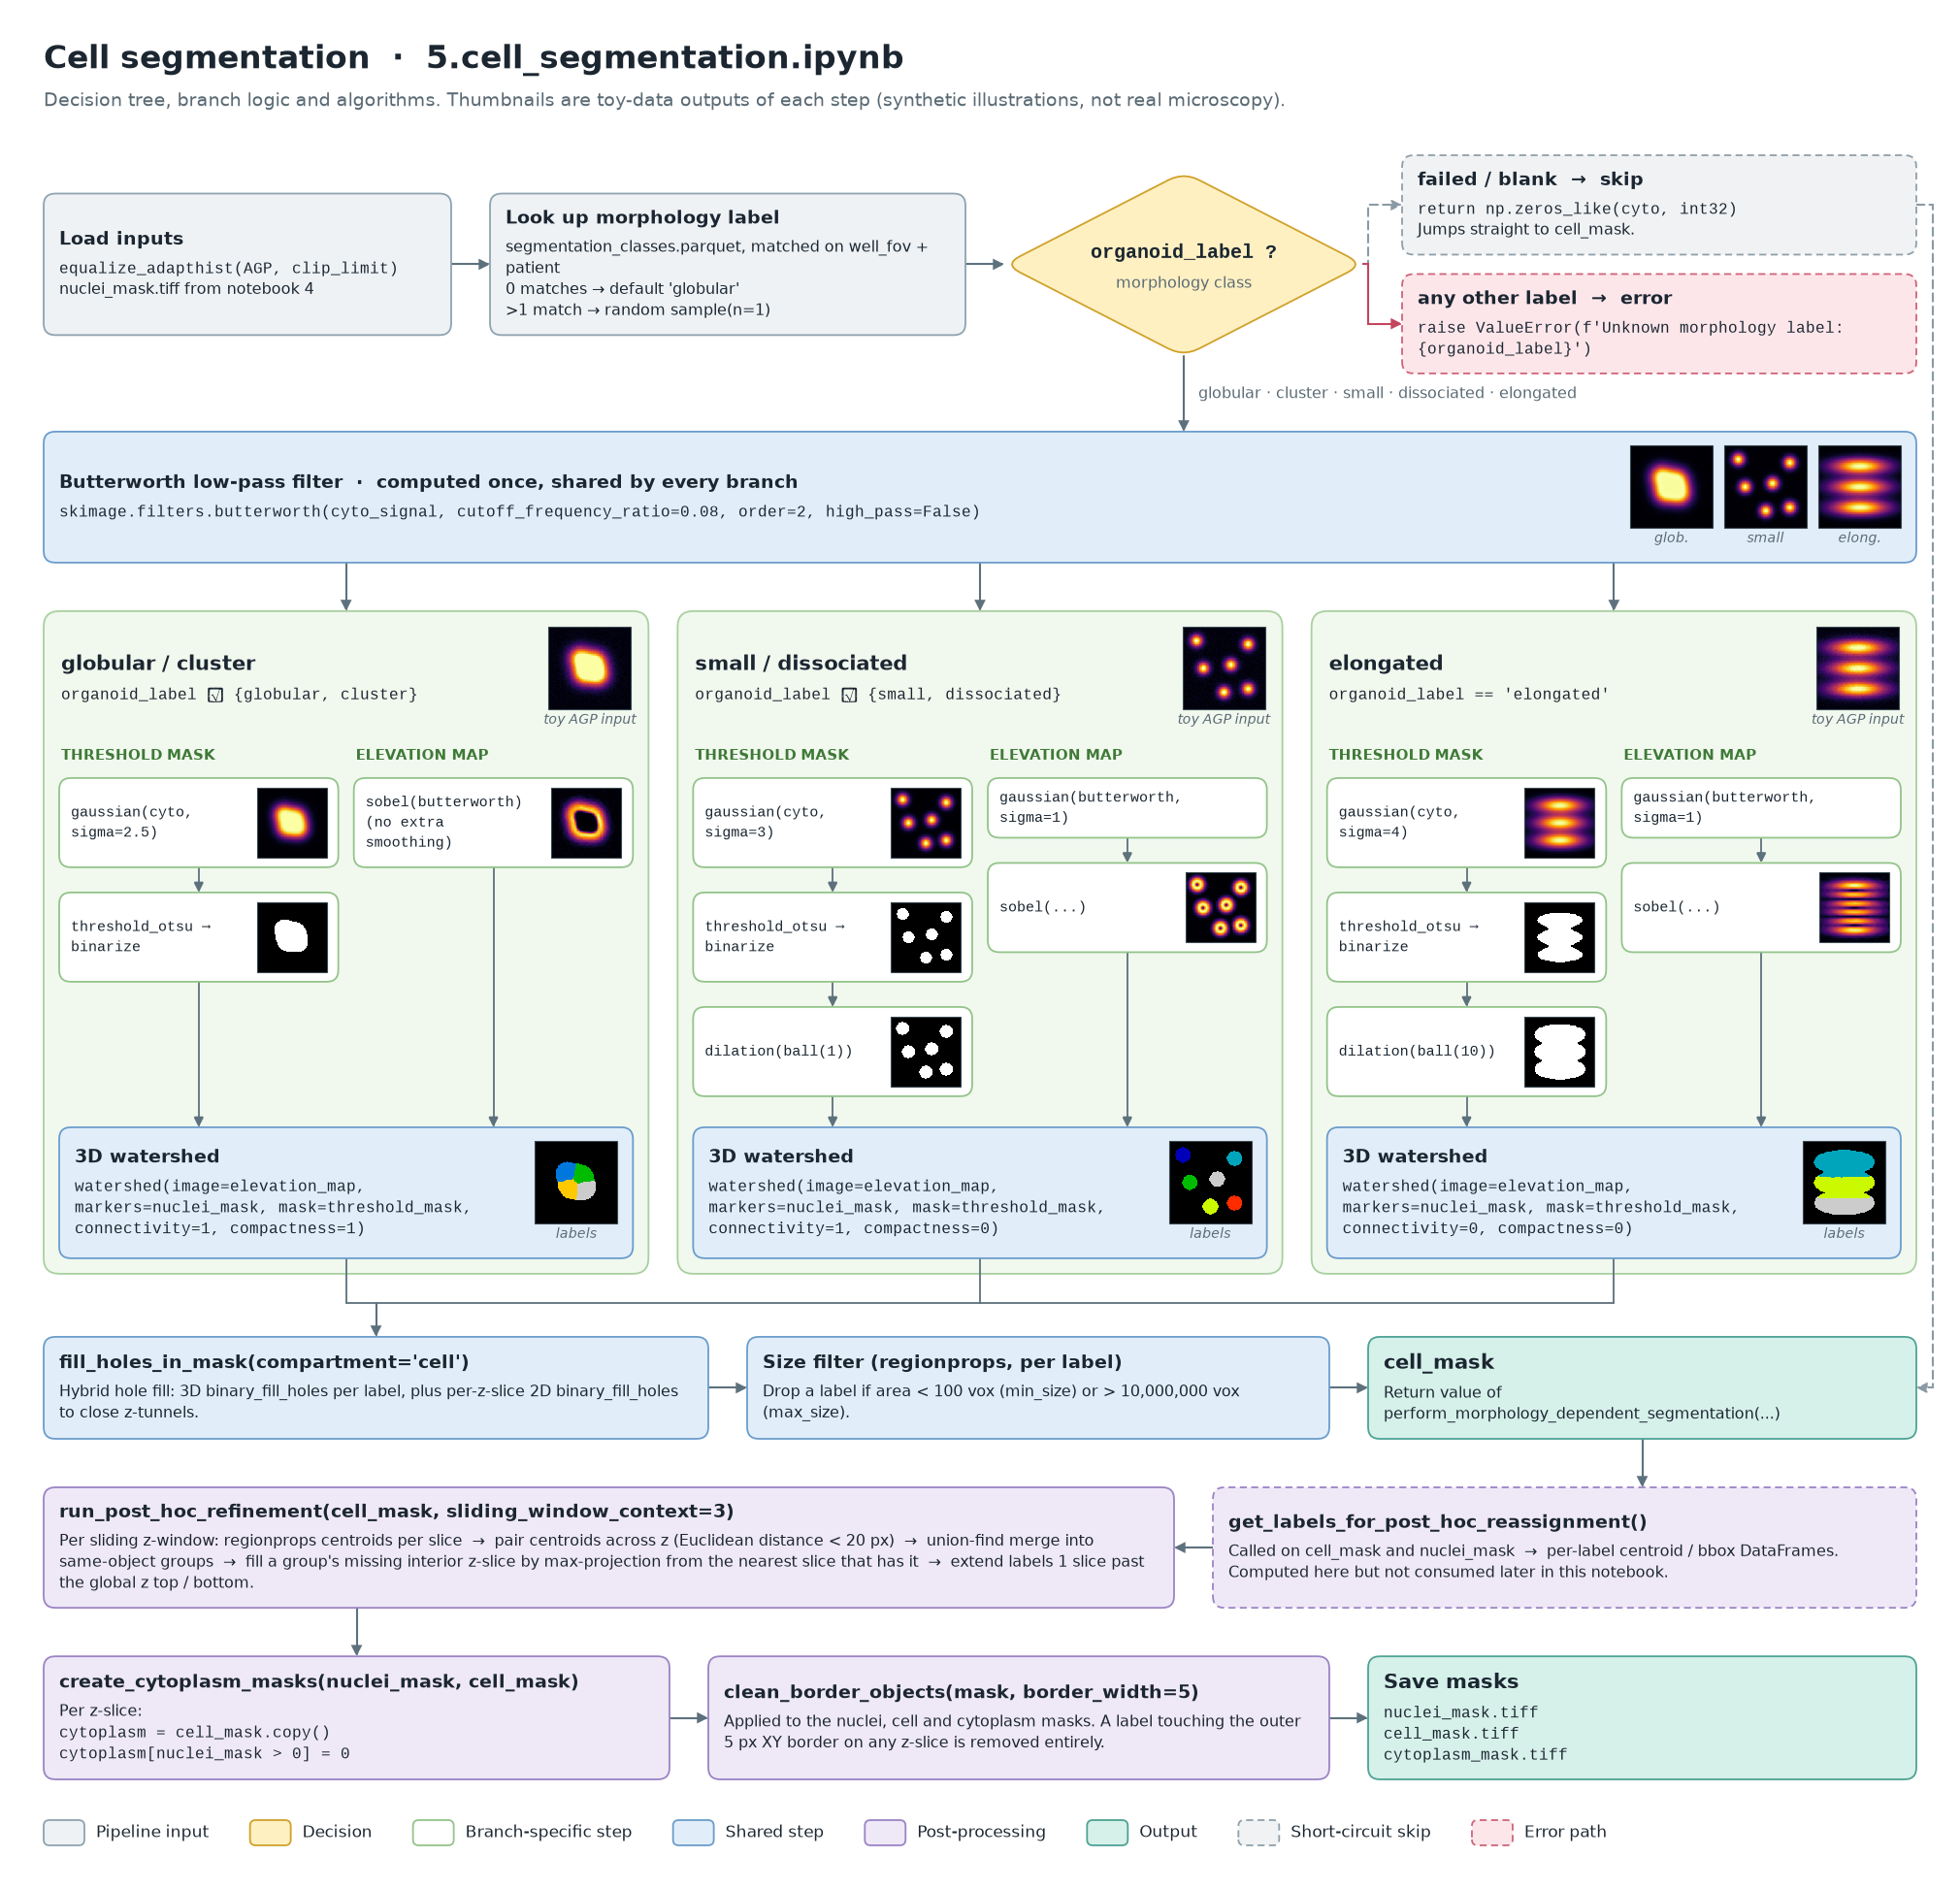

In [4]:
W = 20.0  # figure width, inches (== data units)
M = 0.35  # outer margin
GAP = 0.4  # horizontal gap between boxes in a row
VGAP = 0.5  # vertical gap between rows (room for an arrow)
XR = W - M

fig = plt.figure(figsize=(W, 40), dpi=100)
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, W)
ax.set_ylim(-40, 0)
ax.axis("off")

# ---------------------------------------------------------------- title --
y = -M
ax.text(
    M,
    y,
    "Cell segmentation  ·  5.cell_segmentation.ipynb",
    ha="left",
    va="top",
    fontsize=24,
    fontweight="bold",
    color=INK,
)
ax.text(
    M,
    y - 0.5,
    "Decision tree, branch logic and algorithms. Thumbnails are toy-data outputs "
    "of each step (synthetic illustrations, not real microscopy).",
    ha="left",
    va="top",
    fontsize=13.5,
    color=MUTED,
)
y -= 1.15

# ================================================ ROW 1 (left -> right) ===
load_spec = dict(
    x0=M,
    x1=4.55,
    kind="io",
    title="Load inputs",
    body="`equalize_adapthist(AGP, clip_limit)`\nnuclei_mask.tiff from notebook 4",
)
look_spec = dict(
    x0=4.95,
    x1=9.85,
    kind="io",
    title="Look up morphology label",
    body="segmentation_classes.parquet, matched on well_fov + patient\n"
    "0 matches → default 'globular'\n>1 match → random sample(n=1)",
)
skip_spec = dict(
    x0=14.35,
    x1=XR,
    kind="skip",
    dashed=True,
    title="failed / blank  →  skip",
    body="`return np.zeros_like(cyto, int32)`\nJumps straight to cell_mask.",
)
err_spec = dict(
    x0=14.35,
    x1=XR,
    kind="error",
    dashed=True,
    title="any other label  →  error",
    body="`raise ValueError(f'Unknown morphology label: {organoid_label}')`",
)

h_io = max(box(ax, **load_spec, y1=0, dry=True), box(ax, **look_spec, y1=0, dry=True))
h_skip, h_err = (
    box(ax, **skip_spec, y1=0, dry=True),
    box(ax, **err_spec, y1=0, dry=True),
)
DIA_W, DIA_H = 3.7, 1.9
stack_h = h_skip + 0.2 + h_err
R1 = max(h_io, stack_h, DIA_H)
cy1 = y - R1 / 2

load, look = row(ax, cy1 + h_io / 2, [load_spec, look_spec])
dia = diamond(ax, 12.1, cy1, DIA_W, DIA_H, "organoid_label ?", "morphology class")
skip = box(ax, **skip_spec, y1=cy1 + stack_h / 2)
err = box(ax, **err_spec, y1=skip["y0"] - 0.2)

flow(ax, (load["x1"], cy1), (look["x0"], cy1))
flow(ax, (look["x1"], cy1), dia["left"])
jx = 14.0
flow(
    ax,
    dia["right"],
    (jx, cy1),
    (jx, skip["cy"]),
    (skip["x0"], skip["cy"]),
    dashed=True,
    color="#8a9aa4",
)
flow(
    ax,
    dia["right"],
    (jx, cy1),
    (jx, err["cy"]),
    (err["x0"], err["cy"]),
    color="#c4455e",
)

y = min(cy1 - R1 / 2, dia["bottom"][1]) - VGAP - 0.1

# ============================================ shared Butterworth (full) ===
TAGS = {
    "globular / cluster": "glob.",
    "small / dissociated": "small",
    "elongated": "elong.",
}
bw = box(
    ax,
    M,
    XR,
    y,
    kind="shared",
    title="Butterworth low-pass filter  ·  computed once, shared by every branch",
    body="`skimage.filters.butterworth(cyto_signal, cutoff_frequency_ratio=0.08, "
    "order=2, high_pass=False)`",
    thumbs=[(RESULTS[k]["butterworth"], "inferno", TAGS[k]) for k in TAGS],
    thumb_size=0.85,
)
flow(ax, dia["bottom"], (dia["cx"], bw["y1"]))
ax.text(
    dia["cx"] + 0.15,
    (dia["bottom"][1] + bw["y1"]) / 2,
    "globular · cluster · small · dissociated · elongated",
    ha="left",
    va="center",
    fontsize=11.5,
    color=MUTED,
)

# ===================================================== branch columns ===
COLS = list(BRANCH_PARAMS)
CGAP = 0.3
COL_W = (W - 2 * M - 2 * CGAP) / 3
col_x0 = {k: M + i * (COL_W + CGAP) for i, k in enumerate(COLS)}
PIN = 0.16  # panel inner padding
LGAP = 0.16  # gap between the two lanes

branch_defs = {
    "globular / cluster": dict(
        labels="organoid_label ∈ {globular, cluster}",
        thresh=[
            ("gaussian(cyto, sigma=2.5)", "smoothed", "inferno"),
            ("threshold_otsu → binarize", "otsu", "gray"),
        ],
        elev=[("sobel(butterworth)\n(no extra smoothing)", "elevation", "inferno")],
        ws="connectivity=1, compactness=1",
    ),
    "small / dissociated": dict(
        labels="organoid_label ∈ {small, dissociated}",
        thresh=[
            ("gaussian(cyto, sigma=3)", "smoothed", "inferno"),
            ("threshold_otsu → binarize", "otsu", "gray"),
            ("dilation(ball(1))", "binary", "gray"),
        ],
        elev=[
            ("gaussian(butterworth, sigma=1)", None, None),
            ("sobel(...)", "elevation", "inferno"),
        ],
        ws="connectivity=1, compactness=0",
    ),
    "elongated": dict(
        labels="organoid_label == 'elongated'",
        thresh=[
            ("gaussian(cyto, sigma=4)", "smoothed", "inferno"),
            ("threshold_otsu → binarize", "otsu", "gray"),
            ("dilation(ball(10))", "binary", "gray"),
        ],
        elev=[
            ("gaussian(butterworth, sigma=1)", None, None),
            ("sobel(...)", "elevation", "inferno"),
        ],
        ws="connectivity=0, compactness=0",
    ),
}

panel_top = bw["y0"] - VGAP
hdr_specs = [
    dict(
        x0=col_x0[k] + 0.02,
        x1=col_x0[k] + COL_W - 0.02,
        kind="panel",
        frame=False,
        title=k,
        title_size=15,
        body="`" + branch_defs[k]["labels"] + "`",
        thumbs=[(RESULTS[k]["cyto"], "inferno", "toy AGP input")],
        thumb_size=0.85,
    )
    for k in COLS
]
hdrs = dict(zip(COLS, row(ax, panel_top - 0.02, hdr_specs)))

lane_top = min(h["y0"] for h in hdrs.values()) - 0.05
lane_w = (COL_W - 2 * PIN - LGAP) / 2
lane_ends = {}
for k in COLS:
    x0 = col_x0[k] + PIN
    res = RESULTS[k]
    flow(ax, (col_x0[k] + COL_W / 2, bw["y0"]), (col_x0[k] + COL_W / 2, panel_top))
    ends = []
    for li, (lane_name, steps) in enumerate(
        [
            ("THRESHOLD MASK", branch_defs[k]["thresh"]),
            ("ELEVATION MAP", branch_defs[k]["elev"]),
        ]
    ):
        lx0 = x0 + li * (lane_w + LGAP)
        ax.text(
            lx0 + 0.02,
            lane_top,
            lane_name,
            ha="left",
            va="top",
            fontsize=10.5,
            fontweight="bold",
            color="#3f7a37",
        )
        yy, prev = lane_top - 0.3, None
        for text, key, cmap in steps:
            n = box(
                ax,
                lx0,
                lx0 + lane_w,
                yy,
                kind="sub",
                body="\n".join(f"`{t}`" for t in text.split("\n")),
                body_size=11,
                thumbs=[(res[key], cmap, None)] if key else (),
                thumb_size=0.72,
                pad_x=0.12,
                pad_y=0.1,
            )
            if prev:
                flow(ax, (prev["cx"], prev["y0"]), (n["cx"], n["y1"]), lw=1.3)
            prev, yy = n, n["y0"] - 0.26
        ends.append(prev)
    lane_ends[k] = ends

ws_top = min(e["y0"] for ends in lane_ends.values() for e in ends) - 0.32
ws_specs = [
    dict(
        x0=col_x0[k] + PIN,
        x1=col_x0[k] + COL_W - PIN,
        kind="shared",
        title="3D watershed",
        body=f"`watershed(image=elevation_map, markers=nuclei_mask, "
        f"mask=threshold_mask, {branch_defs[k]['ws']})`",
        thumbs=[(RESULTS[k]["labels"], "nipy_spectral", "labels")],
        thumb_size=0.85,
    )
    for k in COLS
]
ws = dict(zip(COLS, row(ax, ws_top, ws_specs)))
for k in COLS:
    for e in lane_ends[k]:
        flow(ax, (e["cx"], e["y0"]), (e["cx"], ws_top), lw=1.3)
panel_bot = min(n["y0"] for n in ws.values()) - PIN
for k in COLS:
    _rrect(
        ax,
        col_x0[k],
        panel_bot,
        col_x0[k] + COL_W,
        panel_top,
        "panel",
        radius=0.16,
        zorder=0.5,
    )

# ======================================= ROW 4 (left -> right), merge in ==
y = panel_bot - VGAP - 0.15
fill_h, size_f, cell = row(
    ax,
    y,
    [
        dict(
            x0=M,
            x1=7.2,
            kind="shared",
            title="fill_holes_in_mask(compartment='cell')",
            body="Hybrid hole fill: 3D binary_fill_holes per label, plus per-z-slice 2D "
            "binary_fill_holes to close z-tunnels.",
        ),
        dict(
            x0=7.2 + GAP,
            x1=13.6,
            kind="shared",
            title="Size filter (regionprops, per label)",
            body="Drop a label if area < 100 vox (min_size) or > 10,000,000 vox (max_size).",
        ),
        dict(
            x0=13.6 + GAP,
            x1=XR,
            kind="terminal",
            title="cell_mask",
            title_size=15,
            body="Return value of perform_morphology_dependent_segmentation(...)",
        ),
    ],
)
bus_y = panel_bot - 0.3
xs = [ws[k]["cx"] for k in COLS]
ws_y0 = min(n["y0"] for n in ws.values())
for x in xs:
    flow(ax, (x, ws_y0), (x, bus_y), head=False, lw=1.3)
flow(ax, (min(xs), bus_y), (max(xs), bus_y), head=False, lw=1.3)
flow(ax, (fill_h["cx"], bus_y), (fill_h["cx"], y))
flow(ax, (fill_h["x1"], fill_h["cy"]), (size_f["x0"], size_f["cy"]))
flow(ax, (size_f["x1"], size_f["cy"]), (cell["x0"], cell["cy"]))
# skip path: failed / blank goes straight to cell_mask down the right margin
sx = XR + 0.17
flow(
    ax,
    (skip["x1"], skip["cy"]),
    (sx, skip["cy"]),
    (sx, cell["cy"]),
    (cell["x1"], cell["cy"]),
    dashed=True,
    color="#8a9aa4",
)

# ======================================== ROW 5 (right -> left) =========
y = cell["y0"] - VGAP
refine, labels_n = row(
    ax,
    y,
    [
        dict(
            x0=M,
            x1=12.0,
            kind="post",
            title="run_post_hoc_refinement(cell_mask, sliding_window_context=3)",
            body="Per sliding z-window: regionprops centroids per slice  →  pair centroids across z "
            "(Euclidean distance < 20 px)  →  union-find merge into same-object groups  →  "
            "fill a group's missing interior z-slice by max-projection from the nearest slice "
            "that has it  →  extend labels 1 slice past the global z top / bottom.",
        ),
        dict(
            x0=12.0 + GAP,
            x1=XR,
            kind="post",
            dashed=True,
            title="get_labels_for_post_hoc_reassignment()",
            body="Called on cell_mask and nuclei_mask  →  per-label centroid / bbox DataFrames. "
            "Computed here but not consumed later in this notebook.",
        ),
    ],
)
flow(ax, (cell["cx"], cell["y0"]), (cell["cx"], y))
flow(ax, (labels_n["x0"], labels_n["cy"]), (refine["x1"], refine["cy"]))

# ======================================== ROW 6 (left -> right) =========
y = refine["y0"] - VGAP
cyto_n, border_n, save_n = row(
    ax,
    y,
    [
        dict(
            x0=M,
            x1=6.8,
            kind="post",
            title="create_cytoplasm_masks(nuclei_mask, cell_mask)",
            body="Per z-slice:\n`cytoplasm = cell_mask.copy()`\n`cytoplasm[nuclei_mask > 0] = 0`",
        ),
        dict(
            x0=6.8 + GAP,
            x1=13.6,
            kind="post",
            title="clean_border_objects(mask, border_width=5)",
            body="Applied to the nuclei, cell and cytoplasm masks. A label touching the outer 5 px "
            "XY border on any z-slice is removed entirely.",
        ),
        dict(
            x0=13.6 + GAP,
            x1=XR,
            kind="terminal",
            title="Save masks",
            title_size=15,
            body="`nuclei_mask.tiff`\n`cell_mask.tiff`\n`cytoplasm_mask.tiff`",
        ),
    ],
)
flow(ax, (cyto_n["cx"], refine["y0"]), (cyto_n["cx"], y))
flow(ax, (cyto_n["x1"], cyto_n["cy"]), (border_n["x0"], border_n["cy"]))
flow(ax, (border_n["x1"], border_n["cy"]), (save_n["x0"], save_n["cy"]))

# ============================================================== legend ==
y = cyto_n["y0"] - 0.42
legend = [
    ("io", False, "Pipeline input"),
    ("decision", False, "Decision"),
    ("sub", False, "Branch-specific step"),
    ("shared", False, "Shared step"),
    ("post", False, "Post-processing"),
    ("terminal", False, "Output"),
    ("skip", True, "Short-circuit skip"),
    ("error", True, "Error path"),
]
x = M
for kind, dashed, label in legend:
    _rrect(ax, x, y - 0.26, x + 0.42, y, kind, dashed=dashed, radius=0.06)
    ax.text(x + 0.54, y - 0.13, label, ha="left", va="center", fontsize=12, color=INK)
    x += 0.54 + _text_w(ax, label, 12) + 0.42
y -= 0.26

# --------------------------------------------- crop to content, no slack --
bottom = y - M
fig.set_size_inches(W, -bottom)
ax.set_ylim(bottom, 0)
plt.show()

## Notes

- **`failed` / `blank` short-circuits the whole function.** The morphology
  lookup can also silently fall back to `'globular'` (no row matched) or
  pick a random row (multiple rows matched) before the decision is even
  made.
- **The Butterworth low-pass filter is computed once**, before the
  `if`/`elif` chain, and is identical input to all three real branches --
  only what happens to it afterwards (extra smoothing before the Sobel
  elevation map) differs.
- **`connectivity=0`** is the literal value passed for the `elongated`
  branch's watershed call (`globular/cluster` and `small/dissociated` both
  use `1`) -- called out here because it stands out, not corrected.
- **`get_labels_for_post_hoc_reassignment`** is called for both `cell_mask`
  and `nuclei_mask` right after cell segmentation finishes, but neither
  resulting DataFrame is consumed later in this notebook version -- the
  actual label-continuity fix is `run_post_hoc_refinement`, which works
  directly on `cell_mask`'s pixels rather than those DataFrames.
- **`clean_border_objects`** removes a label's *entire* 3D object if it
  touches the outer 5 px XY border on *any* z slice, not just the touching
  slice.
